<a href="https://colab.research.google.com/github/TharushiSamarawickrama/DeepLearning_Lab/blob/main/Lab_07_Part_2_Gridworld.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:

# Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
%matplotlib inline


In [6]:
# Environment (GridWorld)
class GridWorld:
    ## Initialise starting data
    def __init__(self):
        # Set information about the gridworld
        self.height = 8
        self.width = 8
        self.grid = np.zeros((self.height, self.width)) - 1

        # Set random start location for the agent
        self.current_location = (4, np.random.randint(0, 5))

        # Set locations for the bomb and the gold
        self.bomb_location = (1, 3)
        self.gold_location = (0, 3)
        self.terminal_states = [self.bomb_location, self.gold_location]

        # Set grid rewards for special cells
        self.grid[self.bomb_location[0], self.bomb_location[1]] = -10
        self.grid[self.gold_location[0], self.gold_location[1]] = 10

        # Set available actions
        self.actions = ['UP', 'DOWN', 'LEFT', 'RIGHT']

    def get_available_actions(self):
        """Returns possible actions"""
        return self.actions

    def agent_on_map(self):
        """Shows agent's position"""
        grid = np.zeros((self.height, self.width))
        grid[self.current_location[0], self.current_location[1]] = 1
        return grid

    def get_reward(self, new_location):
        """Returns the reward for an input position"""
        return self.grid[new_location[0], new_location[1]]

    def make_step(self, action):
        """Moves the agent in the specified direction."""
        last_location = self.current_location

        if action == 'UP':
            if last_location[0] == 0:
                reward = self.get_reward(last_location)
            else:
                self.current_location = (self.current_location[0] - 1, self.current_location[1])
                reward = self.get_reward(self.current_location)

        elif action == 'DOWN':
            if last_location[0] == self.height - 1:
                reward = self.get_reward(last_location)
            else:
                self.current_location = (self.current_location[0] + 1, self.current_location[1])
                reward = self.get_reward(self.current_location)

        elif action == 'LEFT':
            if last_location[1] == 0:
                reward = self.get_reward(last_location)
            else:
                self.current_location = (self.current_location[0], self.current_location[1] - 1)
                reward = self.get_reward(self.current_location)

        elif action == 'RIGHT':
            if last_location[1] == self.width - 1:
                reward = self.get_reward(last_location)
            else:
                self.current_location = (self.current_location[0], self.current_location[1] + 1)
                reward = self.get_reward(self.current_location)

        return reward

    def check_state(self):
        """Check if the agent reached a terminal state"""
        if self.current_location in self.terminal_states:
            return 'TERMINAL'


In [7]:
# Deep Q-Network (Neural Net)
ACTIONS = ['UP', 'DOWN', 'LEFT', 'RIGHT']

class DQN(nn.Module):
    def __init__(self, input_size=2, output_size=4):
        super(DQN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, output_size)
        )
    def forward(self, x):
        return self.net(x)


In [8]:
# DQN Agent Class
class DQNAgent:
    def __init__(self, environment, epsilon=0.1, lr=1e-3, gamma=1.0):
        self.environment = environment
        self.epsilon = epsilon
        self.gamma = gamma
        self.model = DQN()
        self.optimizer = optim.Adam(self.model.parameters(), lr=lr)
        self.loss_fn = nn.MSELoss()

    def state_to_tensor(self, state):
        """Convert (x, y) → normalized tensor"""
        x, y = state
        state_vec = torch.tensor([x / (self.environment.height - 1),
                                  y / (self.environment.width - 1)],
                                  dtype=torch.float32)
        return state_vec

    def choose_action(self, state):
        """Epsilon-greedy action selection"""
        if np.random.rand() < self.epsilon:
            return np.random.choice(ACTIONS)  # explore
        with torch.no_grad():
            state_tensor = self.state_to_tensor(state)
            q_values = self.model(state_tensor)
            action_idx = torch.argmax(q_values).item()
            return ACTIONS[action_idx]

    def learn(self, old_state, action, reward, new_state, done):
        """Train the neural network"""
        old_tensor = self.state_to_tensor(old_state)
        new_tensor = self.state_to_tensor(new_state)

        q_values = self.model(old_tensor)
        q_value = q_values[ACTIONS.index(action)]

        with torch.no_grad():
            q_next = self.model(new_tensor)
            target = reward if done else reward + self.gamma * torch.max(q_next)
        target_tensor = torch.tensor(target, dtype=torch.float32)

        loss = self.loss_fn(q_value, target_tensor)
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()


In [9]:
# Training Function (Play Loop)
def play(environment, agent, trials=500, max_steps_per_episode=1000, learn=False):
    reward_per_episode = []

    for trial in range(trials):
        cumulative_reward = 0
        step = 0
        game_over = False

        while step < max_steps_per_episode and not game_over:
            old_state = environment.current_location
            action = agent.choose_action(old_state)
            reward = environment.make_step(action)
            new_state = environment.current_location

            done = (environment.check_state() == 'TERMINAL')

            if learn:
                agent.learn(old_state, action, reward, new_state, done)

            cumulative_reward += reward
            step += 1

            if done:
                environment.__init__()
                game_over = True

        reward_per_episode.append(cumulative_reward)

    return reward_per_episode


Training with epsilon = 0.1 ...


/tmp/ipython-input-395022907.py:40: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  target_tensor = torch.tensor(target, dtype=torch.float32)


Training with epsilon = 0.5 ...
Training with epsilon = 0.9 ...


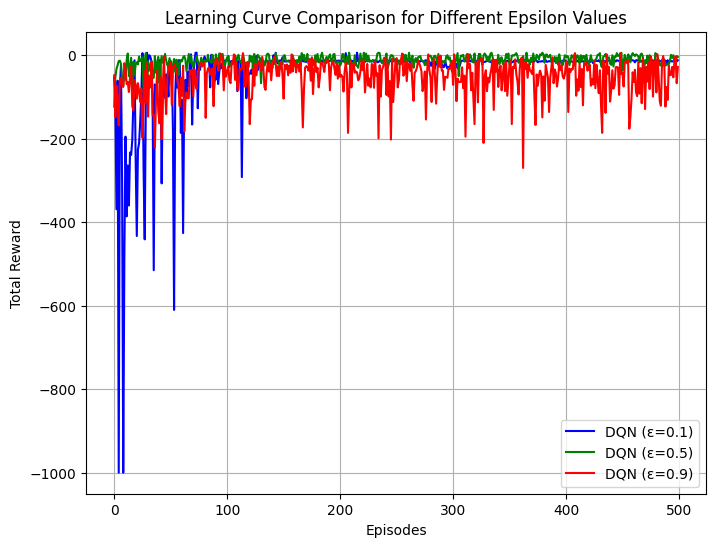

In [10]:
# Run DQN with Multiple Epsilon Values
epsilons = [0.1, 0.5, 0.9]
colors = ['blue', 'green', 'red']

plt.figure(figsize=(8, 6))

for eps, color in zip(epsilons, colors):
    print(f"Training with epsilon = {eps} ...")
    env = GridWorld()
    dqn_agent = DQNAgent(env, epsilon=eps)
    rewards = play(env, dqn_agent, trials=500, learn=True)
    plt.plot(rewards, color=color, label=f"DQN (ε={eps})")

plt.xlabel("Episodes")
plt.ylabel("Total Reward")
plt.title("Learning Curve Comparison for Different Epsilon Values")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
test_states = [(0, 0), (3, 3), (7, 3), (4, 5)]

for state in test_states:
    state_tensor = dqn_agent.state_to_tensor(state)
    with torch.no_grad():
        q_values = dqn_agent.model(state_tensor)
    print(f"State {state} → Q-values {q_values.tolist()}")


State (0, 0) → Q-values [1.7741116285324097, 0.23798978328704834, 2.104414463043213, 2.9302279949188232]
State (3, 3) → Q-values [-4.512223720550537, -6.673689365386963, -4.280088901519775, -5.507708549499512]
State (7, 3) → Q-values [-8.915285110473633, -11.181503295898438, -8.311349868774414, -9.907427787780762]
State (4, 5) → Q-values [-7.163078308105469, -9.36517333984375, -6.909267902374268, -7.864980697631836]
